Библиотеки 

In [12]:
import csv
import random
import math
import matplotlib.pyplot as plt

Функция активации и её тестирование Содержит сигмоид и его производную:

In [13]:
class FanActivation:
    @staticmethod
    def sigmoid(x):
        return 1/(1+math.exp(-x))
    @staticmethod
    def sigmoid_derivative(x):
        sig= FanActivation.sigmoid(x)
        return sig*(1-sig)

y = FanActivation.sigmoid(0)
dy = FanActivation.sigmoid_derivative(0)

print(f"Сигмоида: {y}")
print(f"Производная: {dy}")

Сигмоида: 0.5
Производная: 0.25


Класс 1 нейрон Содержит веса и метод forward:
Класс «Neiron»  -  содержит веса входящих в него связей и метод 
вычисляющей выходное значение нейрона при прямом проходе

In [14]:
class Neiron:
    def __init__(self, num_inputs):

        self.weights = [random.uniform(-0.5, 0.5) for _ in range(num_inputs)]
        
        self.bias = random.uniform(-0.5, 0.5)

        self.last_input = None
        self.last_output = None
    
    def forward(self, inputs):
        self.last_input = inputs
        
        # Считаем взвешенную сумму: сумма(вход_i * вес_i) + смещение
        z = 0.0
        for i in range(len(inputs)):
            z += inputs[i] * self.weights[i]
        z += self.bias
        
        output = FanActivation.sigmoid(z)
        
        self.last_output = output
        
        return output

Класс «DenseLayer»  (слой)  –  содержит массив нейронов и метод 
вычисляющий выходной вектор данного слоя
Содержит массив нейронов и метод forward

In [15]:
class DenseLayer:
    def __init__(self, num_inputs, num_neurons):
        self.neurons = [Neiron(num_inputs) for _ in range(num_neurons)]
        
        
        self.num_inputs = num_inputs#сколько входов у каждого нейрона (размерность входа)
        self.num_neurons = num_neurons #сколько нейронов в слое (размерность выхода)
        
        self.last_output = None
        self.last_input = None
    
    def forward(self, inputs):

        # Запоминаем вход для обратного распространения
        self.last_input = inputs
        

        outputs = []
        for i, neuron in enumerate(self.neurons):
            neuron_output = neuron.forward(inputs)
            outputs.append(neuron_output)
            
            
            if i == 0 and len(self.neurons) > 1:
                print(f"  (Первый нейрон слоя выдал: {round(neuron_output, 3)})")
        
        self.last_output = outputs
        return outputs
    
    def get_weights_info(self):
        #просмотр весов 
        print(f"\nСЛОЙ: {self.num_neurons} нейронов, каждый с {self.num_inputs} входами")
        for i, neuron in enumerate(self.neurons):
            print(f"  Нейрон {i+1}: веса={[round(w, 3) for w in neuron.weights]}, bias={round(neuron.bias, 3)}")

сеть
Класс «Network»
Содержит массив слоев, forward и обучение (backprop):

In [16]:
class Network:
    def __init__(self):
        self.layers = []
        self.loss_history = []  # Для графика
        self.accuracy_history = []  # Для графика
    
    def add_layer(self, layer):
        self.layers.append(layer)
    
    def forward(self, X):
        # Для одного образца
        if isinstance(X[0], (int, float)):
            output = X
            for layer in self.layers:
                output = layer.forward(output)
            return output
        
        # Для нескольких образцов(батч)
        else:
            outputs = []
            for sample in X:
                output = sample
                for layer in self.layers:
                    output = layer.forward(output)
                outputs.append(output)
            return outputs




            #обратное распространение ошибок 
    
    def backward(self, X, y_true, learning_rate):

        y_pred = self.forward(X)
        y_pred_val = y_pred[0]
        

        error = y_pred_val - y_true
        
        # Проходим по слоям с конца в начало , по каждому нейрону применяем производную ,и градиент сумируем ошибки от следующего слоя до выходного , запоминаем для предыдущих слоёв и обновляем веса и сдвиг
        for layer_idx in reversed(range(len(self.layers))):
            layer = self.layers[layer_idx]
            
            for neuron_idx, neuron in enumerate(layer.neurons):
                d_sigmoid = FanActivation.sigmoid_derivative(neuron.last_output)
                

                if layer_idx == len(self.layers) - 1:  
                    neuron_gradient = error * d_sigmoid
                else:  
                    
                    next_layer = self.layers[layer_idx + 1]
                    sum_error = 0
                    for next_neuron in next_layer.neurons:
                        sum_error += next_neuron.weights[neuron_idx] * next_neuron.last_error
                    neuron_gradient = sum_error * d_sigmoid
                
                neuron.last_error = neuron_gradient  
                
               
                for i in range(len(neuron.weights)):
                    delta = learning_rate * neuron_gradient * neuron.last_input[i]
                    neuron.weights[i] -= delta
                
                
                delta_b = learning_rate * neuron_gradient
                neuron.bias -= delta_b
        
        # Возвращаем ошибку
        return abs(error)
    
    def train(self, X_train, y_train, X_val, y_val, epochs=100, learning_rate=0.1):
        print(f"\n ОБУЧЕНИЕ НА {len(X_train)} ПРИМЕРАХ")
        print(f"   Валидация на {len(X_val)} примерах")
        print(f"   Скорость обучения: {learning_rate}, Эпох: {epochs}")
        print("-" * 60)
        
        for epoch in range(epochs):
            # Обучающая выборка
            total_loss = 0
            for i in range(len(X_train)):
                loss = self.backward(X_train[i], y_train[i], learning_rate)
                total_loss += loss
            train_loss = total_loss / len(X_train)
            
            # Валидационная выборка
            val_correct = 0
            for i in range(len(X_val)):
                pred = self.forward(X_val[i])[0]
                if (pred >= 0.5 and y_val[i] == 1) or (pred < 0.5 and y_val[i] == 0):
                    val_correct += 1
            val_acc = val_correct / len(X_val)
            
            # Сохраняем для графиков
            self.loss_history.append(train_loss)
            self.accuracy_history.append(val_acc)
            
            # Выводим прогресс
            if (epoch + 1) % 10 == 0:
                print(f"   Эпоха {epoch+1:3d}: Loss = {train_loss:.4f}, Val Acc = {val_acc:.2%}")
        
        print("-" * 60)
        print(f"✅ Обучение завершено!")
    
    def predict_one(self, sample):
      # соло тестирование
        pred = self.forward(sample)[0]
        return pred, 1 if pred >= 0.5 else 0

диабет 4 признака 
Создание и обучение сети под задачу (вариант 5 - диабет)
4 входных признака (выбирает пользователь)

Нормализация данных

Два класса (0 и 1)

Обучение на датасете

In [17]:
def load_diabetes_data(filename="diabetes.csv"):

    data = []
    targets = []
    
    with open(filename, 'r') as file:
        reader = csv.reader(file)
        header = next(reader)  # Заголовки
        print(f"Заголовки: {header}")
        
        for row in reader:
            if len(row) < 9:
                continue
            
            # Все 8 признаков
            features = [
                float(row[0]), float(row[1]), float(row[2]), float(row[3]),
                float(row[4]), float(row[5]), float(row[6]), float(row[7])
            ]
            outcome = int(row[8])  # 0 или 1
            
            data.append(features)
            targets.append(outcome)
    
    print(f"Загружено {len(data)} записей")
    print(f"Класс 0: {targets.count(0)}")
    print(f"Класс 1: {targets.count(1)}")
    return data, targets, header

def normalize_data(data):
    #нормализация через мин max худшее приложение на свете 
    data = list(data)
    num_features = len(data[0])
    
    # Находим минимум и максимум для каждого признака
    min_vals = [float('inf')] * num_features
    max_vals = [float('-inf')] * num_features
    
    for sample in data:
        for i in range(num_features):
            if sample[i] < min_vals[i]:
                min_vals[i] = sample[i]
            if sample[i] > max_vals[i]:
                max_vals[i] = sample[i]
    
    print(f"\n  Диапазоны признаков:")
    for i in range(num_features):
        print(f"  Признак {i+1}: [{min_vals[i]:.2f}, {max_vals[i]:.2f}]")
    
    # Нормализация
    normalized_data = []
    for sample in data:
        norm_sample = []
        for i in range(num_features):
            if max_vals[i] - min_vals[i] == 0:
                norm_val = 0.5  # Если все значения одинаковые
            else:
                norm_val = (sample[i] - min_vals[i]) / (max_vals[i] - min_vals[i])
            norm_sample.append(norm_val)
        normalized_data.append(norm_sample)
    
    return normalized_data, min_vals, max_vals

def select_features(data, feature_indices):
    # только выбранные признаки 
    selected_data = []
    for sample in data:
        selected_sample = [sample[i] for i in feature_indices]
        selected_data.append(selected_sample)
    return selected_data

def train_val_test_split(data, targets, train_ratio=0.7, val_ratio=0.15):

    paired = list(zip(data, targets))
    random.shuffle(paired)  # Перемешиваем
    
    n = len(paired)
    train_idx = int(n * train_ratio)
    val_idx = int(n * (train_ratio + val_ratio))
    
    train = paired[:train_idx]
    val = paired[train_idx:val_idx]
    test = paired[val_idx:]
    
    # Распаковываем
    X_train = [p[0] for p in train]
    y_train = [p[1] for p in train]
    X_val = [p[0] for p in val]
    y_val = [p[1] for p in val]
    X_test = [p[0] for p in test]
    y_test = [p[1] for p in test]
    
    return X_train, y_train, X_val, y_val, X_test, y_test

def get_user_feature_selection(header):
    print("\n ДОСТУПНЫЕ ПРИЗНАКИ (0-7):")
    for i, name in enumerate(header[:-1]):  # Без Outcome
        print(f"  {i}: {name}")
    
    while True:
        try:
            print("\nВыберите 4 признака (введите индексы через пробел):")
            indices = list(map(int, input("-> ").strip().split()))
            
            if len(indices) != 4:
                print(" Нужно выбрать ровно 4 признака!")
                continue
            
            if any(i < 0 or i > 7 for i in indices):
                print(" Индексы должны быть от 0 до 7!")
                continue
            
            selected_names = [header[i] for i in indices]
            print(f"\n Выбраны: {', '.join(selected_names)}")
            return indices, selected_names
            
        except ValueError:
            print(" Введите числа через пробел!")

In [18]:
print(" АНАЛИЗ ДАННЫХ О ДИАБЕТЕ")
print("="*60)

# Загрузка
print("\n1. ЗАГРУЗКА ДАННЫХ")
data, targets, header = load_diabetes_data("diabetes.csv")

# Выбор признаков пользователем
feature_indices, feature_names = get_user_feature_selection(header)

# Выбор признаков
print("\n2. ВЫБОР ПРИЗНАКОВ")
data_selected = select_features(data, feature_indices)
print(f"   Выбрано {len(data_selected[0])} признака: {', '.join(feature_names)}")

# Нормализация
print("\n3. НОРМАЛИЗАЦИЯ")
data_normalized, min_vals, max_vals = normalize_data(data_selected)

# Разделение на train/val/test
print("\n4. РАЗДЕЛЕНИЕ ДАННЫХ")
X_train, y_train, X_val, y_val, X_test, y_test = train_val_test_split(
    data_normalized, targets, train_ratio=0.7, val_ratio=0.15
)

print(f"   Обучающая выборка: {len(X_train)} образцов")
print(f"   Валидационная выборка: {len(X_val)} образцов")
print(f"   Тестовая выборка: {len(X_test)} образцов")

 АНАЛИЗ ДАННЫХ О ДИАБЕТЕ

1. ЗАГРУЗКА ДАННЫХ
Заголовки: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Загружено 768 записей
Класс 0: 500
Класс 1: 268

 ДОСТУПНЫЕ ПРИЗНАКИ (0-7):
  0: Pregnancies
  1: Glucose
  2: BloodPressure
  3: SkinThickness
  4: Insulin
  5: BMI
  6: DiabetesPedigreeFunction
  7: Age

Выберите 4 признака (введите индексы через пробел):

 Выбраны: Glucose, BloodPressure, SkinThickness, Insulin

2. ВЫБОР ПРИЗНАКОВ
   Выбрано 4 признака: Glucose, BloodPressure, SkinThickness, Insulin

3. НОРМАЛИЗАЦИЯ

  Диапазоны признаков:
  Признак 1: [0.00, 199.00]
  Признак 2: [0.00, 122.00]
  Признак 3: [0.00, 99.00]
  Признак 4: [0.00, 846.00]

4. РАЗДЕЛЕНИЕ ДАННЫХ
   Обучающая выборка: 537 образцов
   Валидационная выборка: 115 образцов
   Тестовая выборка: 116 образцов


In [19]:
print("\n5. СОЗДАНИЕ НЕЙРОННОЙ СЕТИ")
print("-" * 40)

# Создаем сеть
net = Network()

# Добавляем 3 слоя
net.add_layer(DenseLayer(num_inputs=4, num_neurons=4))   # Входной слой: 4 -> 4
net.add_layer(DenseLayer(num_inputs=4, num_neurons=8))   # Скрытый слой: 4 -> 8
net.add_layer(DenseLayer(num_inputs=8, num_neurons=1))   # Выходной слой: 8 -> 1

print(f"\n Архитектура: 4 - 4 → 8 → 1-0\1")


5. СОЗДАНИЕ НЕЙРОННОЙ СЕТИ
----------------------------------------

 Архитектура: 4 - 4 → 8 → 1-0


In [20]:
print("\n6. ОБУЧЕНИЕ СЕТИ")
print("="*60)

# Обучаем
net.train(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    epochs=100,
    learning_rate=0.01
)


6. ОБУЧЕНИЕ СЕТИ

 ОБУЧЕНИЕ НА 537 ПРИМЕРАХ
   Валидация на 115 примерах
   Скорость обучения: 0.01, Эпох: 100
------------------------------------------------------------
  (Первый нейрон слоя выдал: 0.586)
  (Первый нейрон слоя выдал: 0.396)
  (Первый нейрон слоя выдал: 0.581)
  (Первый нейрон слоя выдал: 0.392)
  (Первый нейрон слоя выдал: 0.626)
  (Первый нейрон слоя выдал: 0.402)
  (Первый нейрон слоя выдал: 0.592)
  (Первый нейрон слоя выдал: 0.393)
  (Первый нейрон слоя выдал: 0.596)
  (Первый нейрон слоя выдал: 0.394)
  (Первый нейрон слоя выдал: 0.566)
  (Первый нейрон слоя выдал: 0.392)
  (Первый нейрон слоя выдал: 0.593)
  (Первый нейрон слоя выдал: 0.398)
  (Первый нейрон слоя выдал: 0.581)
  (Первый нейрон слоя выдал: 0.392)
  (Первый нейрон слоя выдал: 0.603)
  (Первый нейрон слоя выдал: 0.396)
  (Первый нейрон слоя выдал: 0.581)
  (Первый нейрон слоя выдал: 0.392)
  (Первый нейрон слоя выдал: 0.649)
  (Первый нейрон слоя выдал: 0.406)
  (Первый нейрон слоя выдал: 0.6)
 


7. РЕЗУЛЬТАТЫ


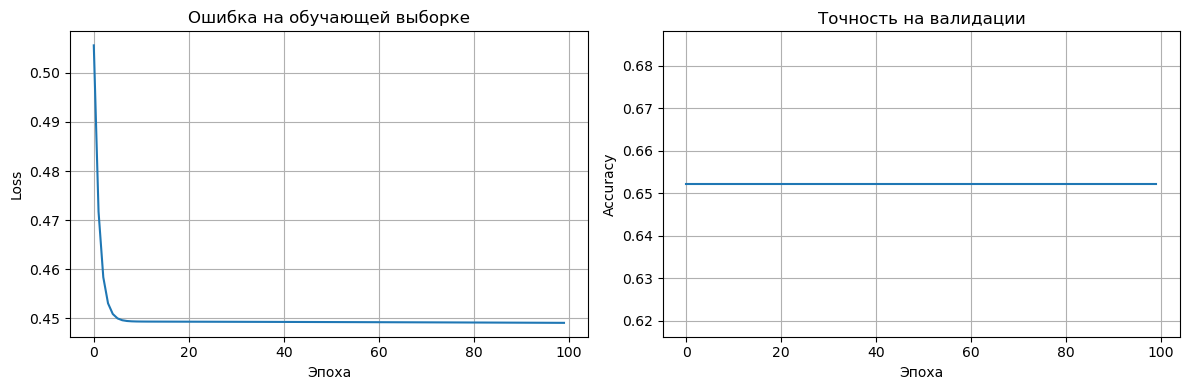


    ТЕСТОВАЯ ВЫБОРКА:
  (Первый нейрон слоя выдал: 0.605)
  (Первый нейрон слоя выдал: 0.387)
  (Первый нейрон слоя выдал: 0.634)
  (Первый нейрон слоя выдал: 0.397)
  (Первый нейрон слоя выдал: 0.582)
  (Первый нейрон слоя выдал: 0.383)
  (Первый нейрон слоя выдал: 0.597)
  (Первый нейрон слоя выдал: 0.387)
  (Первый нейрон слоя выдал: 0.598)
  (Первый нейрон слоя выдал: 0.385)
  (Первый нейрон слоя выдал: 0.532)
  (Первый нейрон слоя выдал: 0.378)
  (Первый нейрон слоя выдал: 0.624)
  (Первый нейрон слоя выдал: 0.394)
  (Первый нейрон слоя выдал: 0.596)
  (Первый нейрон слоя выдал: 0.394)
  (Первый нейрон слоя выдал: 0.584)
  (Первый нейрон слоя выдал: 0.382)
  (Первый нейрон слоя выдал: 0.587)
  (Первый нейрон слоя выдал: 0.385)
  (Первый нейрон слоя выдал: 0.619)
  (Первый нейрон слоя выдал: 0.393)
  (Первый нейрон слоя выдал: 0.63)
  (Первый нейрон слоя выдал: 0.392)
  (Первый нейрон слоя выдал: 0.614)
  (Первый нейрон слоя выдал: 0.388)
  (Первый нейрон слоя выдал: 0.574)
  (Пер

In [21]:
print("\n7. РЕЗУЛЬТАТЫ")
print("="*60)

# График ошибки
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(net.loss_history)
plt.title('Ошибка на обучающей выборке')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(net.accuracy_history)
plt.title('Точность на валидации')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.grid(True)

plt.tight_layout()
plt.show()

# Оценка на тестовой выборке
print("\n    ТЕСТОВАЯ ВЫБОРКА:")
correct = 0
for i in range(len(X_test)):
    pred = net.forward(X_test[i])[0]
    pred_class = 1 if pred >= 0.5 else 0
    if pred_class == y_test[i]:
        correct += 1

accuracy = correct / len(X_test)
print(f"   Точность: {accuracy * 100:.2f}% ({correct}/{len(X_test)})")

# Показываем несколько примеров
print("\n ПРИМЕРЫ ПРЕДСКАЗАНИЙ (ТЕСТ):")
print("-" * 70)
print(f"{'№':3} {'Правда':8} {'Предсказано':12} {'Вероятность':12} {'Результат':10}")
print("-" * 70)

for i in range(min(10, len(X_test))):
    prob = net.forward(X_test[i])[0]
    pred_class = 1 if prob >= 0.5 else 0
    result = "|/" if pred_class == y_test[i] else "✗"
    print(f"{i+1:3} {y_test[i]:8} {pred_class:12} {prob:.4f}      {result:10}")

In [22]:
print("\n8. ИНТЕРАКТИВНОЕ ТЕСТИРОВАНИЕ")
print("="*60)
print("Введите свои значения для проверки работы сети")

index_to_position = {}
for pos, orig_idx in enumerate(feature_indices):
    index_to_position[orig_idx] = pos

print(f"\n Выбранные признаки: {list(zip(feature_indices, feature_names))}")

while True:
    print(f"\n ВВЕДИТЕ ЗНАЧЕНИЯ ДЛЯ ПРИЗНАКОВ:")
    user_sample = []
    
    for i, name in enumerate(feature_names):
        while True:
            try:
                val = float(input(f"  {name}: "))
                user_sample.append(val)
                break
            except ValueError:
                print(" Введите число!")
    
    # Нормализуем введенные данные
    norm_sample = []
    for i, val in enumerate(user_sample):
        # i - это позиция в выбранных данных (0,1,2,3)
        # feature_indices[i] - исходный индекс признака
        orig_idx = feature_indices[i]
       
        norm_val = (val - min_vals[i]) / (max_vals[i] - min_vals[i])
        
        # Ограничиваем значения диапазоном [0, 1] на всякий случай а то я намаелся 
        norm_val = max(0, min(1, norm_val))
        
        norm_sample.append(norm_val)
    
    print(f"\n    Нормализованные значения: {[round(x, 3) for x in norm_sample]}")
    
    # Получаем предсказание
    prob, pred_class = net.predict_one(norm_sample)
    
    print(f"\n РЕЗУЛЬТАТ:")
    print(f"   Введенные значения: {dict(zip(feature_names, user_sample))}")
    print(f"   Вероятность диабета: {prob:.4f}")
    print(f"   Предсказание: {pred_class} ({'Диабет' if pred_class == 1 else 'Здоров'})")
    
    # Показываем "уверенность"
    confidence = prob if pred_class == 1 else 1 - prob
    print(f"   Уверенность сети: {confidence:.2%}")
    
    again = input("\n Проверить другой образец? (д/н): ").lower()
    if again not in ['д', 'да', 'y', 'yes']:
        break

print("\n" + "="*60)
print(" РАБОТА ЗАВЕРШЕНА")


8. ИНТЕРАКТИВНОЕ ТЕСТИРОВАНИЕ
Введите свои значения для проверки работы сети

 Выбранные признаки: [(1, 'Glucose'), (2, 'BloodPressure'), (3, 'SkinThickness'), (4, 'Insulin')]

 ВВЕДИТЕ ЗНАЧЕНИЯ ДЛЯ ПРИЗНАКОВ:

    Нормализованные значения: [0.503, 0.82, 1, 0.118]
  (Первый нейрон слоя выдал: 0.58)
  (Первый нейрон слоя выдал: 0.392)

 РЕЗУЛЬТАТ:
   Введенные значения: {'Glucose': 100.0, 'BloodPressure': 100.0, 'SkinThickness': 100.0, 'Insulin': 100.0}
   Вероятность диабета: 0.3375
   Предсказание: 0 (Здоров)
   Уверенность сети: 66.25%

 РАБОТА ЗАВЕРШЕНА
